<a href="https://colab.research.google.com/github/DAustinGit/SolubilityML/blob/main/solubility_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
df = pd.read_csv('https://raw.githubusercontent.com/dataprofessor/data/refs/heads/master/delaney_solubility_with_descriptors.csv')
print (df.head())

   MolLogP    MolWt  NumRotatableBonds  AromaticProportion  logS
0   2.5954  167.850                0.0                 0.0 -2.18
1   2.3765  133.405                0.0                 0.0 -2.00
2   2.5938  167.850                1.0                 0.0 -1.74
3   2.0289  133.405                1.0                 0.0 -1.48
4   2.9189  187.375                1.0                 0.0 -3.04


#Data preparation


In [ ]:
Y = df['logS']   # Y is feature used for training
X = df.drop('logS', axis=1)   #X is the feature we are predicting drop logS and axis = 1 --> work in coluns
print (Y.head())
print (X.head())

0   -2.18
1   -2.00
2   -1.74
3   -1.48
4   -3.04
Name: logS, dtype: float64
   MolLogP    MolWt  NumRotatableBonds  AromaticProportion
0   2.5954  167.850                0.0                 0.0
1   2.3765  133.405                0.0                 0.0
2   2.5938  167.850                1.0                 0.0
3   2.0289  133.405                1.0                 0.0
4   2.9189  187.375                1.0                 0.0


###split the dataset into test and training sets


In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split (X, Y, test_size= 0.2, random_state = 100) #splits the data for train and test sets testing set is 20% of data
print (X_train)

     MolLogP    MolWt  NumRotatableBonds  AromaticProportion
107  3.14280  112.216                5.0            0.000000
378 -2.07850  142.070                0.0            0.000000
529 -0.47730  168.152                0.0            0.000000
546 -0.86740  154.125                0.0            0.000000
320  1.62150  100.161                2.0            0.000000
..       ...      ...                ...                 ...
802  3.00254  250.301                1.0            0.842105
53   2.13860   82.146                3.0            0.000000
350  5.76304  256.348                0.0            0.900000
79   3.89960  186.339               10.0            0.000000
792  2.52334  310.297                3.0            0.300000

[915 rows x 4 columns]


#Model Building

##Linear Regression


**trianing the model**

In [ ]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X_train, Y_train)


LinearRegression()

**applying the model to make predictions**

In [ ]:
Y_lr_train_pred = lr.predict(X_train)
Y_lr_test_pred = lr.predict(X_test)

In [ ]:
print (Y_lr_train_pred)

[-2.83668969  0.84208401 -0.50930302 -0.13058053 -1.6269208  -2.86103037
 -2.32208333 -4.16684323 -5.04235077 -2.29737009 -3.15082845 -4.33037208
 -1.43700682 -2.59060064 -7.09025955 -2.32734557 -4.19073421 -2.63904005
 -3.58104074 -3.75929058 -2.5501665  -3.26968347 -2.78911367 -2.69251051
 -0.77437547 -6.61955792 -2.99084623 -2.36975061 -7.18167736 -1.52816491
 -4.81736265 -0.86996608 -7.09025955 -1.87404275 -2.58013247 -4.80953284
 -4.17454084 -1.95444152 -3.50503339 -2.7411418  -1.87131835 -2.45270806
 -3.07252433 -1.48988982 -3.98778754 -1.35216679 -0.16932277 -6.05237002
 -3.29550658  0.30513174 -3.25501463 -5.31993586 -0.4733928  -4.79180882
 -5.82486323 -2.70343539 -3.70838271 -2.4987341  -2.12301018 -3.11393974
 -2.79842053 -1.38274662 -4.3267103  -3.57778946 -3.42356884 -9.15826626
 -6.52588866 -1.75832085 -4.97842312 -1.59255758 -1.91317252 -2.81075595
 -1.14056747 -1.6326702  -1.6269208  -5.33227425 -3.88805074  0.70432882
 -3.99288096 -2.22595859 -2.63405871 -1.80643013 -4

In [ ]:
print (Y_lr_test_pred)

[-3.05722870e+00 -7.77785827e+00 -2.55016650e+00 -2.01523582e+00
 -2.06375990e+00 -9.99672215e-01 -5.94603364e-01 -5.53626003e-01
 -5.72200956e+00 -3.94006681e+00 -3.95496755e+00 -2.29737009e+00
 -1.48980354e+00 -1.48988982e+00 -4.64510806e+00 -1.90396018e+00
 -1.51566313e+00 -3.16424605e+00 -3.70863920e+00 -5.58105660e+00
 -3.25038467e+00 -5.04235077e+00 -5.69194881e+00 -2.14339849e+00
 -4.35689341e+00 -5.03964756e+00 -3.10383618e+00 -4.40286964e+00
 -4.21276272e+00  5.56508349e-01 -1.45537678e+00 -4.41027396e+00
 -2.59668773e+00 -1.53336276e+00 -5.55749874e-01 -1.67111795e+00
 -2.78163675e+00 -3.15395565e+00 -5.27083361e+00 -1.75321446e+00
 -1.53350725e+00 -2.01255666e+00 -6.57559167e+00 -7.89433046e+00
 -5.76437127e+00 -4.16422068e+00 -3.43694663e+00  1.43834212e+00
 -1.12679105e-02 -2.34521849e+00 -1.86480046e+00 -5.03964756e+00
  8.55886378e-01 -3.17679292e+00 -5.06764094e+00 -1.99464442e+00
 -7.77785827e+00 -1.21764693e+00 -9.09541075e-01 -5.04235077e+00
 -2.43898748e+00 -2.84034

###**evaluate model performance**
evaluate the mean square error (MSE) and R^2 error (R2)

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score
lr_train_mse = mean_squared_error(Y_train, Y_lr_train_pred)
lr_train_r2 = r2_score(Y_train, Y_lr_train_pred)
lr_test_mse = mean_squared_error(Y_test, Y_lr_test_pred)
lr_test_r2 = r2_score(Y_test, Y_lr_test_pred)

print ('LR MSE (Train): ',lr_train_mse)
print ('LR R2 (Train): ',lr_train_r2)
print ('LR MSE (Test): ',lr_test_mse)
print ('LR R2 (Test): ',lr_test_r2)
print

LR MSE (Train):  1.0075362951093687
LR R2 (Train):  0.7645051774663391
LR MSE (Test):  1.0206953660861033
LR R2 (Test):  0.7891616188563282


<function print(*args, sep=' ', end='\n', file=None, flush=False)>

In [ ]:
lr_results = pd.DataFrame(['Linear regression', lr_train_mse, lr_train_r2, lr_test_mse, lr_test_r2]).transpose()
lr_results.columns = ['methods', 'Training MSE', 'Training R2', 'Test MSE', 'test R2']
lr_results

,methods,Training MSE,Training R2,Test MSE,test R2
0,Linear regression,1.007536,0.764505,1.020695,0.789162


## **Random Forest**
use RandomForestRegressor because Y (logS) is quantitative if its catagporical use RandomForestClassifier

In [ ]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor (max_depth=3, random_state=100)
rf.fit(X_train, Y_train)

RandomForestRegressor(max_depth=3, random_state=100)

### Applying the model to make predictions





In [ ]:
Y_rf_train_pred = rf.predict(X_train)
Y_rf_test_pred = rf.predict(X_test)

###**evaluate model performance**
evaluate the mean square error (MSE) and R^2 error (R2)

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score
rf_train_mse = mean_squared_error(Y_train, Y_rf_train_pred)
rf_train_r2 = r2_score(Y_train, Y_rf_train_pred)
rf_test_mse = mean_squared_error(Y_test, Y_rf_test_pred)
rf_test_r2 = r2_score(Y_test, Y_rf_test_pred)

print ('LR MSE (Train): ',rf_train_mse)
print ('LR R2 (Train): ',rf_train_r2)
print ('LR MSE (Test): ',rf_test_mse)
print ('LR R2 (Test): ',rf_test_r2)

LR MSE (Train):  0.709282579940429
LR R2 (Train):  0.8342170142156943
LR MSE (Test):  1.0441872804991974
LR R2 (Test):  0.7843090473943699


In [ ]:
rf_results = pd.DataFrame(['Random Forest', rf_train_mse, rf_train_r2, rf_test_mse, rf_test_r2]).transpose()
rf_results.columns = ['methods', 'Training MSE', 'Training R2', 'Test MSE', 'test R2']
rf_results

,methods,Training MSE,Training R2,Test MSE,test R2
0,Random Forest,0.709283,0.834217,1.044187,0.784309


## Stoichastic gradient descent


*   it is important to scale data before
*   we make a pipeline and pass in the standard scalar method



In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import SGDRegressor
from sklearn.preprocessing import StandardScaler

clf = make_pipeline(StandardScaler(), SGDRegressor(penalty= 'l2', max_iter=1000))
clf.fit(X_train, Y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('sgdregressor', SGDRegressor())])

### Applying the model to make predictions








In [ ]:
Y_clf_train_pred = clf.predict(X_train)
Y_clf_test_pred = clf.predict(X_test)

###evaluate model performance
evaluate the mean square error (MSE) and R^2 error (R2)

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score
clf_train_mse = mean_squared_error(Y_train, Y_clf_train_pred)
clf_train_r2 = r2_score(Y_train, Y_clf_train_pred)
clf_test_mse = mean_squared_error(Y_test, Y_clf_test_pred)
clf_test_r2 = r2_score(Y_test, Y_clf_test_pred)

print ('LR MSE (Train): ',clf_train_mse)
print ('LR R2 (Train): ',clf_train_r2)
print ('LR MSE (Test): ',clf_test_mse)
print ('LR R2 (Test): ',clf_test_r2)

LR MSE (Train):  1.0078824864611287
LR R2 (Train):  0.7644242610057201
LR MSE (Test):  1.021714271321738
LR R2 (Test):  0.7889511502507502


In [ ]:
clf_results = pd.DataFrame(['Stoichastic Gradient Descent', clf_train_mse, clf_train_r2, clf_test_mse, clf_test_r2]).transpose()
clf_results.columns = ['methods', 'Training MSE', 'Training R2', 'Test MSE', 'test R2']
clf_results

,methods,Training MSE,Training R2,Test MSE,test R2
0,Stoichastic Gradient Descent,1.007882,0.764424,1.021714,0.788951


##Bayesian Ridge Regression

In [ ]:
from sklearn import linear_model
br = linear_model.BayesianRidge()
br.fit(X_train, Y_train)


BayesianRidge()

### Applying the model to make predictions








In [ ]:
Y_br_train_pred = br.predict(X_train)
Y_br_test_pred = br.predict(X_test)

###evaluate model performance
evaluate the mean square error (MSE) and R^2 error (R2)

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score
br_train_mse = mean_squared_error(Y_train, Y_br_train_pred)
br_train_r2 = r2_score(Y_train, Y_br_train_pred)
br_test_mse = mean_squared_error(Y_test, Y_br_test_pred)
br_test_r2 = r2_score(Y_test, Y_br_test_pred)

print ('LR MSE (Train): ',br_train_mse)
print ('LR R2 (Train): ',br_train_r2)
print ('LR MSE (Test): ',br_test_mse)
print ('LR R2 (Test): ',br_test_r2)

LR MSE (Train):  1.007600068459816
LR R2 (Train):  0.7644902715081925
LR MSE (Test):  1.020381496247132
LR R2 (Test):  0.7892264529007819


In [ ]:
br_results = pd.DataFrame(['Beyesian Ridge Regression', br_train_mse, br_train_r2, br_test_mse, br_test_r2]).transpose()
br_results.columns = ['methods', 'Training MSE', 'Training R2', 'Test MSE', 'test R2']
br_results

,methods,Training MSE,Training R2,Test MSE,test R2
0,Beyesian Ridge Regression,1.0076,0.76449,1.020381,0.789226


## K-nearest neighbours

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
kn = KNeighborsRegressor(n_neighbors=5)
kn.fit (X_train,Y_train)


KNeighborsRegressor()

### Applying the model to make predictions


In [ ]:
Y_kn_train_pred = kn.predict(X_train)
Y_kn_test_pred = kn.predict(X_test)

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score
kn_train_mse = mean_squared_error(Y_train, Y_kn_train_pred)
kn_train_r2 = r2_score(Y_train, Y_kn_train_pred)
kn_test_mse = mean_squared_error(Y_test, Y_kn_test_pred)
kn_test_r2 = r2_score(Y_test, Y_kn_test_pred)

print ('LR MSE (Train): ',kn_train_mse)
print ('LR R2 (Train): ',kn_train_r2)
print ('LR MSE (Test): ',kn_test_mse)
print ('LR R2 (Test): ',kn_test_r2)

LR MSE (Train):  0.9924817863606558
LR R2 (Train):  0.7680239180648847
LR MSE (Test):  1.5592718679475983
LR R2 (Test):  0.6779113853905672


In [ ]:
kn_results = pd.DataFrame(['K-Nearest neighbours', kn_train_mse, kn_train_r2, kn_test_mse, kn_test_r2]).transpose()
kn_results.columns = ['methods', 'Training MSE', 'Training R2', 'Test MSE', 'test R2']
kn_results

,methods,Training MSE,Training R2,Test MSE,test R2
0,K-Nearest neighbours,0.992482,0.768024,1.559272,0.677911


## Bayesian Ridge with standard scalar pipeline

In [ ]:
from sklearn import linear_model
from sklearn.preprocessing import StandardScaler

brp = make_pipeline(StandardScaler(), linear_model.BayesianRidge())
brp.fit(X_train, Y_train)




brp.fit(X_train, Y_train)


Pipeline(steps=[('standardscaler', StandardScaler()),
                ('bayesianridge', BayesianRidge())])

### Applying the model to make predictions


In [ ]:
Y_brp_train_pred = brp.predict(X_train)
Y_brp_test_pred = brp.predict(X_test)

###evaluate model performance
evaluate the mean square error (MSE) and R^2 error (R2)

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score
brp_train_mse = mean_squared_error(Y_train, Y_brp_train_pred)
brp_train_r2 = r2_score(Y_train, Y_brp_train_pred)
brp_test_mse = mean_squared_error(Y_test, Y_brp_test_pred)
brp_test_r2 = r2_score(Y_test, Y_brp_test_pred)

print ('LR MSE (Train): ',brp_train_mse)
print ('LR R2 (Train): ',brp_train_r2)
print ('LR MSE (Test): ',brp_test_mse)
print ('LR R2 (Test): ',brp_test_r2)

LR MSE (Train):  1.007544057509488
LR R2 (Train):  0.7645033631346396
LR MSE (Test):  1.0210332499135069
LR R2 (Test):  0.7890918243989892


In [ ]:
brp_results = pd.DataFrame(['Beyesian Ridge Pipeline', brp_train_mse, brp_train_r2, brp_test_mse, brp_test_r2]).transpose()
brp_results.columns = ['methods', 'Training MSE', 'Training R2', 'Test MSE', 'test R2']
brp_results

,methods,Training MSE,Training R2,Test MSE,test R2
0,Beyesian Ridge Pipeline,1.007544,0.764503,1.021033,0.789092


## BR KNN Ensemble

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn import linear_model
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import StackingRegressor
from sklearn.model_selection import GridSearchCV

base_learners = [
    ('lr', linear_model.BayesianRidge()),
    ('knn', KNeighborsRegressor())
]

stacking_ensemble = StackingRegressor(
    estimators=base_learners,
    final_estimator=RidgeCV(),
    cv = 3


)
pipeline = Pipeline([
  ('scaler', StandardScaler()),
  ('stack', stacking_ensemble)
])

param_grid = {


    # Tune the KNN model hidden inside the stack step
    'stack__knn__n_neighbors': [3, 5, 7, 11],

    # Tune the weights parameter of the KNN model inside the stack step
    'stack__knn__weights': ['uniform', 'distance']
}
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train, Y_train)

# 6. Output the results
print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best CV R² Score: {grid_search.best_score_:.4f}")
print(f"Test Set R² Score: {grid_search.score(X_test, Y_test):.4f}")


Best Parameters: {'stack__knn__n_neighbors': 11, 'stack__knn__weights': 'distance'}
Best CV R² Score: 0.8677
Test Set R² Score: 0.8745


In [ ]:
Y_bk_train_pred = grid_search.predict(X_train)
Y_bk_test_pred = grid_search.predict(X_test)

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score
bk_train_mse = mean_squared_error(Y_train, Y_bk_train_pred)
bk_train_r2 = r2_score(Y_train, Y_bk_train_pred)
bk_test_mse = mean_squared_error(Y_test, Y_bk_test_pred)
bk_test_r2 = r2_score(Y_test, Y_bk_test_pred)

print ('LR MSE (Train): ',bk_train_mse)
print ('LR R2 (Train): ',bk_train_r2)
print ('LR MSE (Test): ',bk_test_mse)
print ('LR R2 (Test): ',bk_test_r2)

LR MSE (Train):  0.02682936125310656
LR R2 (Train):  0.9937290838080369
LR MSE (Test):  0.607494493461096
LR R2 (Test):  0.8745138267393411


In [ ]:
bk_results = pd.DataFrame(['BR KNN Ensemble', bk_train_mse, bk_train_r2, bk_test_mse, bk_test_r2]).transpose()
bk_results.columns = ['methods', 'Training MSE', 'Training R2', 'Test MSE', 'test R2']
bk_results

,methods,Training MSE,Training R2,Test MSE,test R2
0,BR KNN Ensemble,0.026829,0.993729,0.607494,0.874514


## Gaussian Process Regressor

In [ ]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

kernel = 1*RBF(length_scale=[1.0,1.0,1.0,1.0], length_scale_bounds=(1e-2, 1e2))

gpr = make_pipeline(StandardScaler(), GaussianProcessRegressor(kernel=kernel,n_restarts_optimizer=1, normalize_y=True,  alpha=1e-3))
gpr.fit(X_train, Y_train)






Pipeline(steps=[('standardscaler', StandardScaler()),
                ('gaussianprocessregressor',
                 GaussianProcessRegressor(alpha=0.001,
                                          kernel=1**2 * RBF(length_scale=[1, 1, 1, 1]),
                                          n_restarts_optimizer=1,
                                          normalize_y=True))])

In [ ]:
Y_gpr_train_pred = gpr.predict(X_train)
Y_gpr_test_pred = gpr.predict(X_test)

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score
gpr_train_mse = mean_squared_error(Y_train, Y_gpr_train_pred)
gpr_train_r2 = r2_score(Y_train, Y_gpr_train_pred)
gpr_test_mse = mean_squared_error(Y_test, Y_gpr_test_pred)
gpr_test_r2 = r2_score(Y_test, Y_gpr_test_pred)

print ('GPR MSE (Train): ',gpr_train_mse)
print ('GPR R2 (Train): ',gpr_train_r2)
print ('GPR MSE (Test): ',gpr_test_mse)
print ('GPR R2 (Test): ',gpr_test_r2)

GPR MSE (Train):  0.019866306007129183
GPR R2 (Train):  0.995356581961109
GPR MSE (Test):  2.046241526202714
GPR R2 (Test):  0.5773212408440164


In [ ]:
gpr_results = pd.DataFrame(['Gaussian Process Regressor', gpr_train_mse, gpr_train_r2, gpr_test_mse, gpr_test_r2]).transpose()
gpr_results.columns = ['methods', 'Training MSE', 'Training R2', 'Test MSE', 'test R2']
gpr_results

,methods,Training MSE,Training R2,Test MSE,test R2
0,Gaussian Process Regressor,0.019866,0.995357,2.046242,0.577321


##Model Comparison

In [ ]:
df_models = pd.concat([lr_results, rf_results, clf_results, br_results, brp_results, kn_results, bk_results, gpr_results], axis=0).reset_index(drop=True)
df_models

,methods,Training MSE,Training R2,Test MSE,test R2
0,Linear regression,1.007536,0.764505,1.020695,0.789162
1,Random Forest,0.709283,0.834217,1.044187,0.784309
2,Stoichastic Gradient Descent,1.007882,0.764424,1.021714,0.788951
3,Beyesian Ridge Regression,1.0076,0.76449,1.020381,0.789226
4,Beyesian Ridge Pipeline,1.007544,0.764503,1.021033,0.789092
5,K-Nearest neighbours,0.992482,0.768024,1.559272,0.677911
6,BR KNN Ensemble,0.026829,0.993729,0.607494,0.874514
7,Gaussian Process Regressor,0.019866,0.995357,2.046242,0.577321


#Data visualisation of prediction results


##Linear Regression

Text(0.5, 0, 'Experimental LogS')

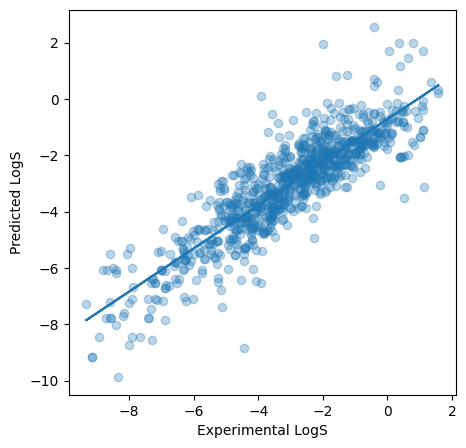

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
plt.figure(figsize=(5,5))
plt.scatter (x=Y_train, y = Y_lr_train_pred, alpha=0.3)
z = np.polyfit(Y_train, Y_lr_train_pred,1)
p = np.poly1d(z)

plt.plot(Y_train, p(Y_train))
plt.ylabel('Predicted LogS')
plt.xlabel('Experimental LogS')

###Residuals plot

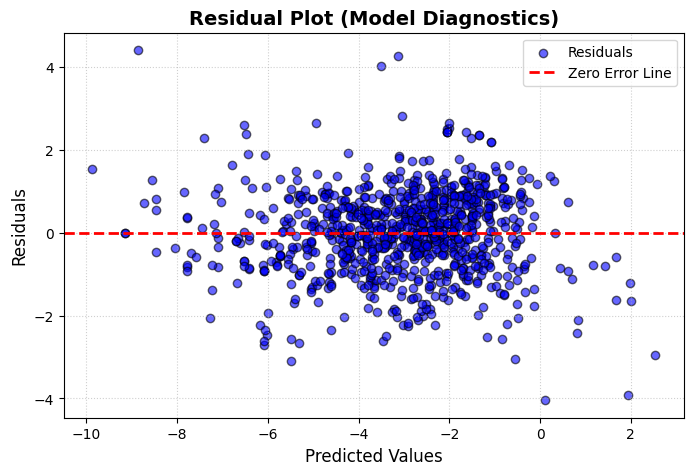

In [ ]:
lr_train_res = Y_train - Y_lr_train_pred
plt.figure(figsize=(8, 5))

# Scatter plot of predicted vs residuals
plt.scatter(Y_lr_train_pred, lr_train_res, color='blue', alpha=0.6, edgecolors='k', label='Residuals')

# Add a horizontal line at y=0
plt.axhline(y=0, color='red', linestyle='--', linewidth=2, label='Zero Error Line')

# Labels and Styling
plt.title('Residual Plot (Model Diagnostics)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Values', fontsize=12)
plt.ylabel('Residuals', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

# Display the plot
plt.show()

##Random Forrests

Text(0.5, 0, 'Experimental LogS')

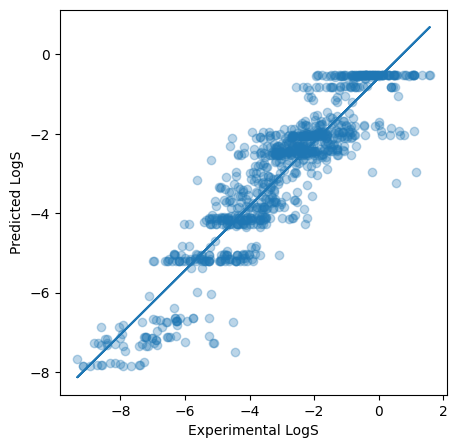

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
plt.figure(figsize=(5,5))
plt.scatter (x=Y_train, y = Y_rf_train_pred, alpha=0.3)

z = np.polyfit(Y_train, Y_rf_train_pred,1)
p = np.poly1d(z)

plt.plot(Y_train, p(Y_train))
plt.ylabel('Predicted LogS')
plt.xlabel('Experimental LogS')

###Residuals plot

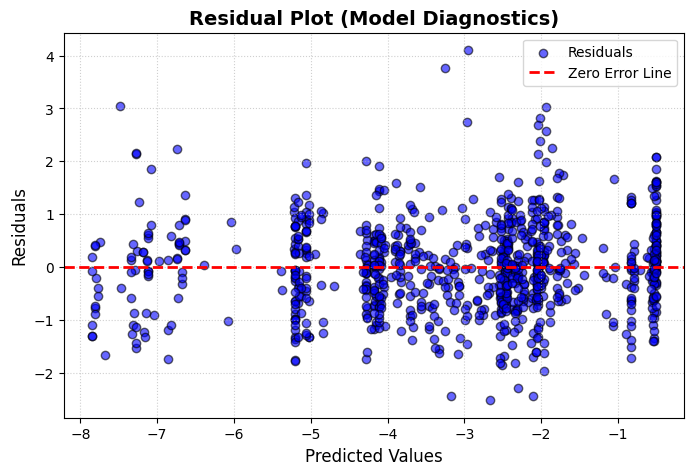

In [ ]:
Y_train_rf = Y_train - Y_rf_train_pred
plt.figure(figsize=(8, 5))

# Scatter plot of predicted vs residuals
plt.scatter(Y_rf_train_pred, Y_train_rf, color='blue', alpha=0.6, edgecolors='k', label='Residuals')

# Add a horizontal line at y=0
plt.axhline(y=0, color='red', linestyle='--', linewidth=2, label='Zero Error Line')

# Labels and Styling
plt.title('Residual Plot (Model Diagnostics)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Values', fontsize=12)
plt.ylabel('Residuals', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

# Display the plot
plt.show()

##Stoichastic Gradient Descent




Text(0.5, 0, 'Experimental LogS')

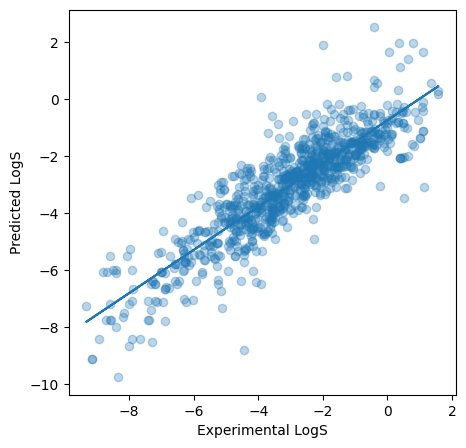

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
plt.figure(figsize=(5,5))
plt.scatter (x=Y_train, y = Y_clf_train_pred, alpha=0.3)

z = np.polyfit(Y_train, Y_clf_train_pred,1)
p = np.poly1d(z)

plt.plot(Y_train, p(Y_train))
plt.ylabel('Predicted LogS')
plt.xlabel('Experimental LogS')

###Residuals plot

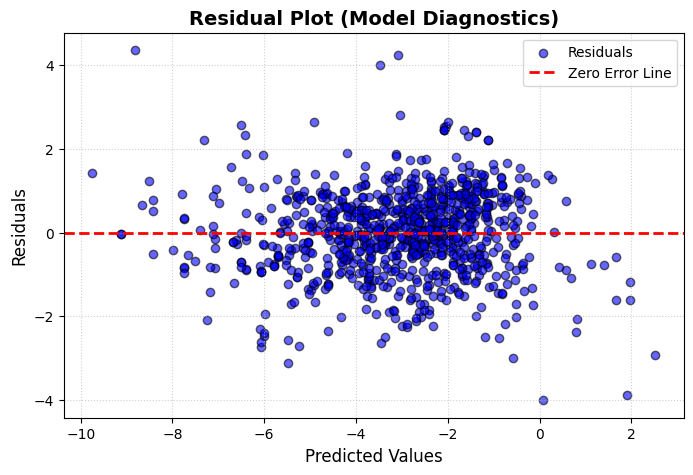

In [ ]:
clf_train_res = Y_train - Y_clf_train_pred
plt.figure(figsize=(8, 5))

# Scatter plot of predicted vs residuals
plt.scatter(Y_clf_train_pred, clf_train_res, color='blue', alpha=0.6, edgecolors='k', label='Residuals')

# Add a horizontal line at y=0
plt.axhline(y=0, color='red', linestyle='--', linewidth=2, label='Zero Error Line')

# Labels and Styling
plt.title('Residual Plot (Model Diagnostics)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Values', fontsize=12)
plt.ylabel('Residuals', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

# Display the plot
plt.show()

##Beyesian Ridge Regression


Text(0.5, 0, 'Experimental LogS')

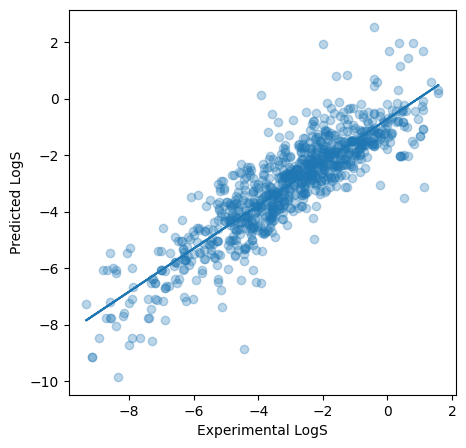

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
plt.figure(figsize=(5,5))
plt.scatter (x=Y_train, y = Y_br_train_pred, alpha=0.3)

z = np.polyfit(Y_train, Y_br_train_pred,1)
p = np.poly1d(z)

plt.plot(Y_train, p(Y_train))
plt.ylabel('Predicted LogS')
plt.xlabel('Experimental LogS')

###Residuals plot

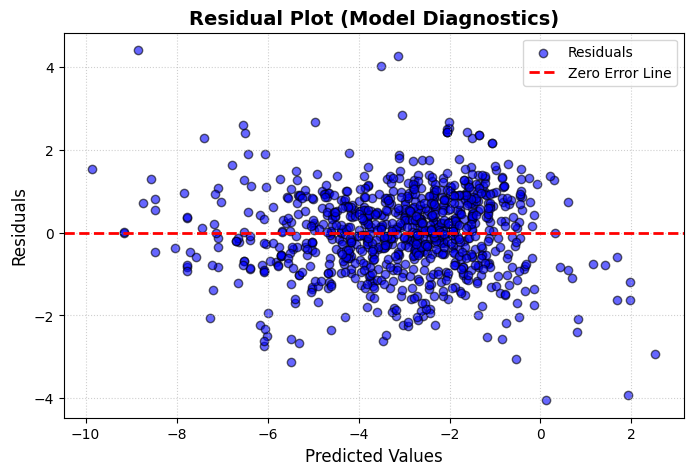

In [ ]:
br_train_res = Y_train - Y_br_train_pred
plt.figure(figsize=(8, 5))

# Scatter plot of predicted vs residuals
plt.scatter(Y_br_train_pred, br_train_res, color='blue', alpha=0.6, edgecolors='k', label='Residuals')

# Add a horizontal line at y=0
plt.axhline(y=0, color='red', linestyle='--', linewidth=2, label='Zero Error Line')

# Labels and Styling
plt.title('Residual Plot (Model Diagnostics)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Values', fontsize=12)
plt.ylabel('Residuals', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

# Display the plot
plt.show()

##Baysian Ridge pipeline

Text(0.5, 0, 'Experimental LogS')

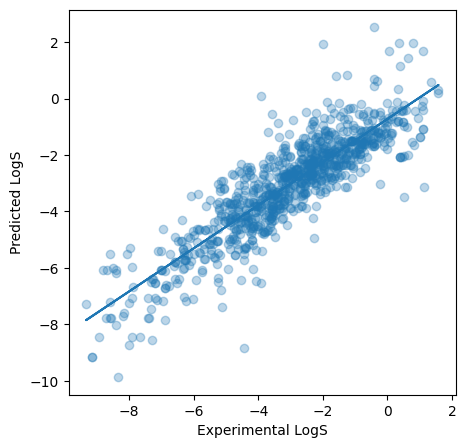

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
plt.figure(figsize=(5,5))
plt.scatter (x=Y_train, y = Y_brp_train_pred, alpha=0.3)

z = np.polyfit(Y_train, Y_brp_train_pred,1)
p = np.poly1d(z)

plt.plot(Y_train, p(Y_train))
plt.ylabel('Predicted LogS')
plt.xlabel('Experimental LogS')

###Residuals plot

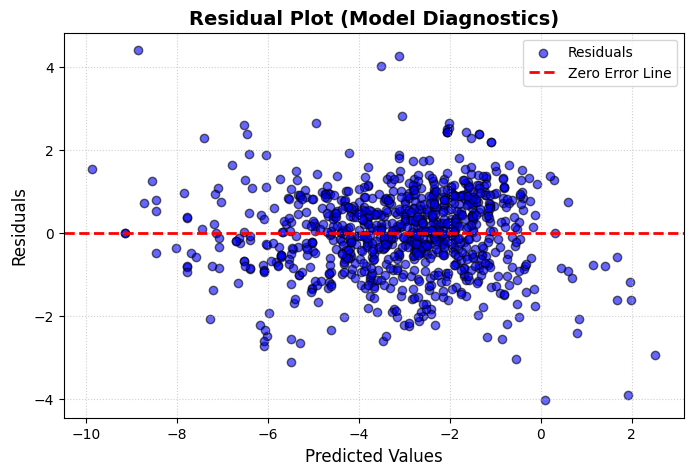

In [ ]:
brp_train_res = Y_train - Y_brp_train_pred
plt.figure(figsize=(8, 5))

# Scatter plot of predicted vs residuals
plt.scatter(Y_brp_train_pred, brp_train_res, color='blue', alpha=0.6, edgecolors='k', label='Residuals')

# Add a horizontal line at y=0
plt.axhline(y=0, color='red', linestyle='--', linewidth=2, label='Zero Error Line')

# Labels and Styling
plt.title('Residual Plot (Model Diagnostics)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Values', fontsize=12)
plt.ylabel('Residuals', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

# Display the plot
plt.show()

##K nearest neighbours regression

Text(0.5, 0, 'Experimental LogS')

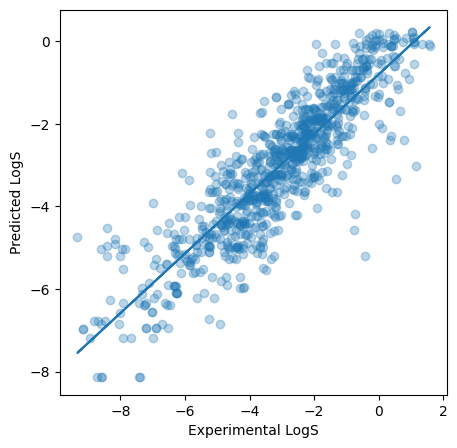

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
plt.figure(figsize=(5,5))
plt.scatter (x=Y_train, y = Y_kn_train_pred, alpha=0.3)

z = np.polyfit(Y_train, Y_kn_train_pred,1)
p = np.poly1d(z)

plt.plot(Y_train, p(Y_train))
plt.ylabel('Predicted LogS')
plt.xlabel('Experimental LogS')

###Residuals plot

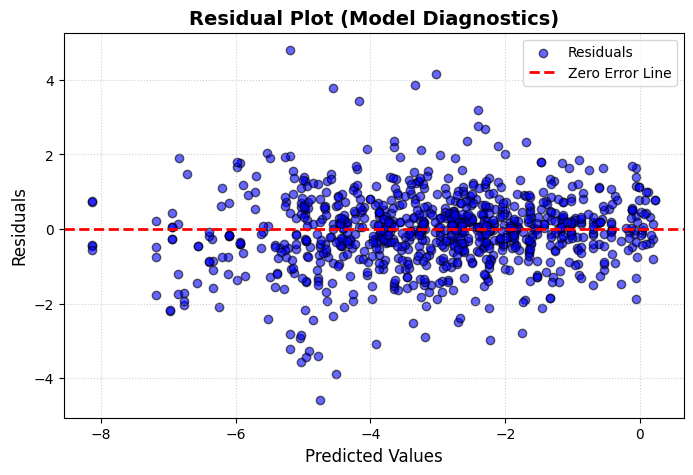

In [ ]:
kn_train_res = Y_train - Y_kn_train_pred
plt.figure(figsize=(8, 5))

# Scatter plot of predicted vs residuals
plt.scatter(Y_kn_train_pred, kn_train_res, color='blue', alpha=0.6, edgecolors='k', label='Residuals')

# Add a horizontal line at y=0
plt.axhline(y=0, color='red', linestyle='--', linewidth=2, label='Zero Error Line')

# Labels and Styling
plt.title('Residual Plot (Model Diagnostics)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Values', fontsize=12)
plt.ylabel('Residuals', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

# Display the plot
plt.show()

##BR KNN Ensemble

this model is over fitting consider adgusting params

Text(0.5, 0, 'Experimental LogS')

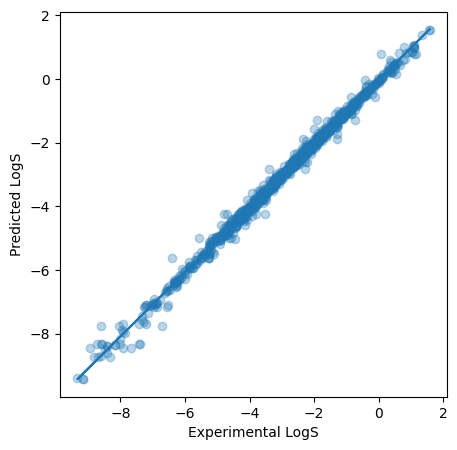

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
plt.figure(figsize=(5,5))
plt.scatter (x=Y_train, y = Y_bk_train_pred, alpha=0.3)

z = np.polyfit(Y_train, Y_bk_train_pred,1)
p = np.poly1d(z)

plt.plot(Y_train, p(Y_train))
plt.ylabel('Predicted LogS')
plt.xlabel('Experimental LogS')

###Residuals plot

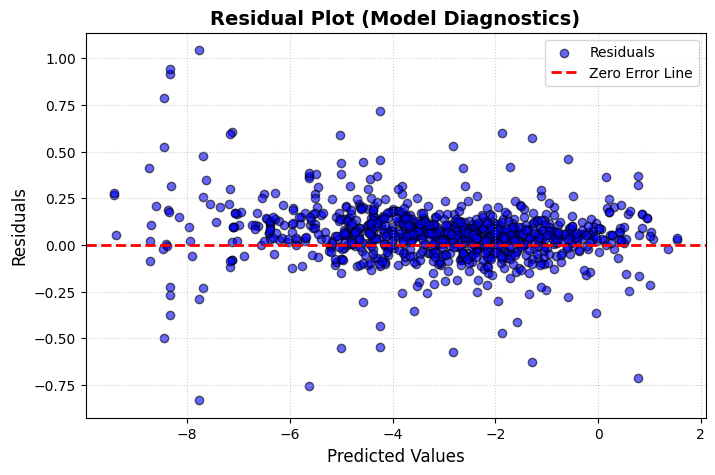

In [ ]:
bk_train_res = Y_train - Y_bk_train_pred
plt.figure(figsize=(8, 5))

# Scatter plot of predicted vs residuals
plt.scatter(Y_bk_train_pred, bk_train_res, color='blue', alpha=0.6, edgecolors='k', label='Residuals')

# Add a horizontal line at y=0
plt.axhline(y=0, color='red', linestyle='--', linewidth=2, label='Zero Error Line')

# Labels and Styling
plt.title('Residual Plot (Model Diagnostics)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Values', fontsize=12)
plt.ylabel('Residuals', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

# Display the plot
plt.show()

##Gaussian Process Regression

Text(0.5, 0, 'Experimental LogS')

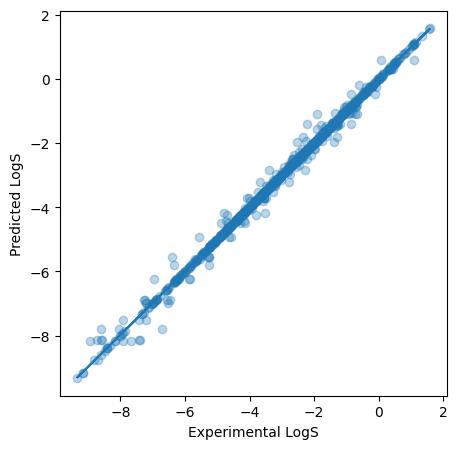

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
plt.figure(figsize=(5,5))
plt.scatter (x=Y_train, y = Y_gpr_train_pred, alpha=0.3)

z = np.polyfit(Y_train, Y_gpr_train_pred,1)
p = np.poly1d(z)

plt.plot(Y_train, p(Y_train))
plt.ylabel('Predicted LogS')
plt.xlabel('Experimental LogS')

###Residuals plot

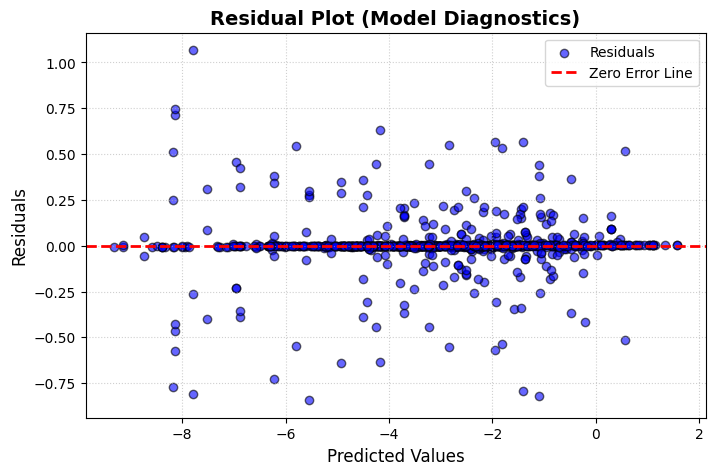

In [ ]:
gpr_train_res = Y_train - Y_gpr_train_pred
plt.figure(figsize=(8, 5))

# Scatter plot of predicted vs residuals
plt.scatter(Y_gpr_train_pred, gpr_train_res, color='blue', alpha=0.6, edgecolors='k', label='Residuals')

# Add a horizontal line at y=0
plt.axhline(y=0, color='red', linestyle='--', linewidth=2, label='Zero Error Line')

# Labels and Styling
plt.title('Residual Plot (Model Diagnostics)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Values', fontsize=12)
plt.ylabel('Residuals', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

# Display the plot
plt.show()